In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gumbel_r

plt.rcParams['text.usetex'] = True
plt.rcParams['mathtext.fontset'] = 'stix'
plt.rcParams['font.family'] = 'STIXGeneral'
plt.rcParams['axes.labelweight'] = 'bold'
plt.rc('font', size=25)

# Global parameters
WF_LEN           = 32
MU_MIN           = 10
MU_MAX           = 11
WIDTH            = 1
SIGNAL_TO_NOISE  = 1000
SIGMA_VALUES     = [0.1, 0.5, 1]
N_WFS            = 2000
DT               = 5
UPSAMPLE_FACTOR  = 10 

def generate_wf( wf_len, mu_min, mu_max, width, signal_to_noise_ratio, noise_amplitude=1.0):
    x = np.arange(wf_len)
    mu = np.random.uniform(mu_min, mu_max)
    baseline = np.random.normal(loc=0.0, scale=noise_amplitude, size=wf_len)
    pulse = signal_to_noise_ratio * gumbel_r.pdf(x, loc=mu, scale=width)
    return baseline + pulse, mu

def analyze_wf_pair(wf1, wf2):
    d = wf1 - wf2
    return 1 if np.argmax(d) > np.argmin(d) else -1

def compute_comparison_matrix_sum(wfs):
    n = len(wfs)
    m = np.zeros((n, n))
    for i in range(n):
        for j in range(n):
            if i != j:
                try:
                    m[i, j] = analyze_wf_pair(wfs[i], wfs[j])
                except ValueError:
                    pass
    return m.sum(axis=1) / (n - 1)

def reorder_wfs_by_fom(wfs, fom):
    return wfs[np.argsort(fom)[::-1]]
    
def interpolate_averaged_wf(wfs, upsample_factor):
    groups = np.array_split(wfs, upsample_factor)
    weighted_means = []
    for g in groups:
        n = g.shape[0]
        idxs = np.arange(n)
        m = np.median(idxs)
        sigma = n / 6
        weights = np.exp(-((idxs - m)**2) / (2 * sigma**2))
        weights /= weights.sum()
        weighted_means.append(np.average(g, axis=0, weights=weights))
    return np.vstack(weighted_means).T.flatten()

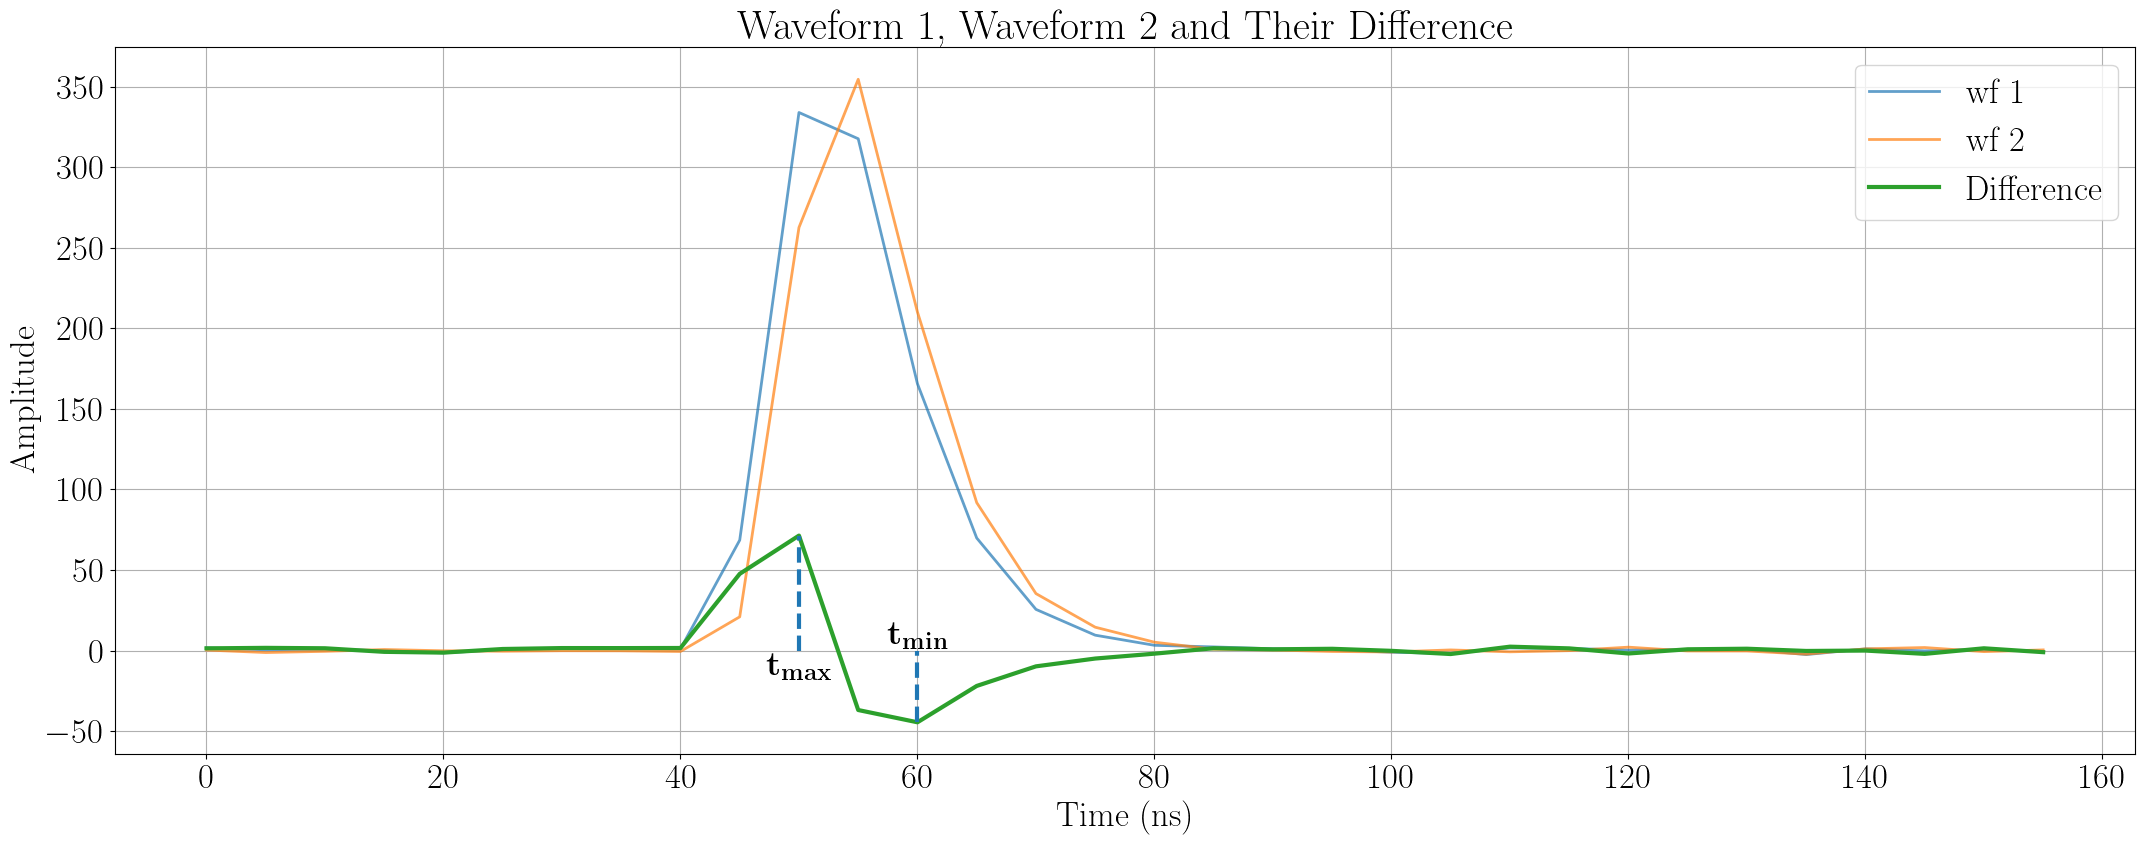

In [2]:
# Generate wfs
wfs = []
mus = []
for _ in range(2):
    wf, mu = generate_wf( wf_len=WF_LEN, mu_min=MU_MIN, mu_max=MU_MAX, width=WIDTH, signal_to_noise_ratio=SIGNAL_TO_NOISE)
    wfs.append(wf)
    mus.append(mu)
wfs = np.vstack(wfs)
mus = np.array(mus)

# Pick two wfs for comparison
wf1 = wfs[0]
wf2 = wfs[1]
diff = wf1 - wf2

# Time axis with sample interval in nanoseconds
t = np.linspace(0, wf1.size-1, wf1.size, endpoint=True)*DT

# Plot everything on one canvas
plt.figure(figsize=(22, 9))
plt.plot(t, wf1,  label='wf 1', linewidth=2, alpha=0.7)
plt.plot(t, wf2,  label='wf 2', linewidth=2, alpha=0.7)
plt.plot(t, diff, label='Difference',     linewidth=3, alpha=1.0)

# Mark extrema of the difference
t_max = t[np.argmax(diff)]
t_min = t[np.argmin(diff)]
plt.vlines(t_max, 0, np.max(diff), linestyle='--', linewidth=3)
plt.annotate(r"$\mathbf{t_{max}}$", xy=(t_max, 0), va="top",   ha="center")
plt.vlines(t_min, np.min(diff), 0, linestyle='--', linewidth=3)
plt.annotate(r"$\mathbf{t_{min}}$", xy=(t_min, 0), va="bottom", ha="center")

plt.xlabel(r"Time (ns)")
plt.ylabel(r"Amplitude")
plt.title(r"Waveform 1, Waveform 2 and Their Difference")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


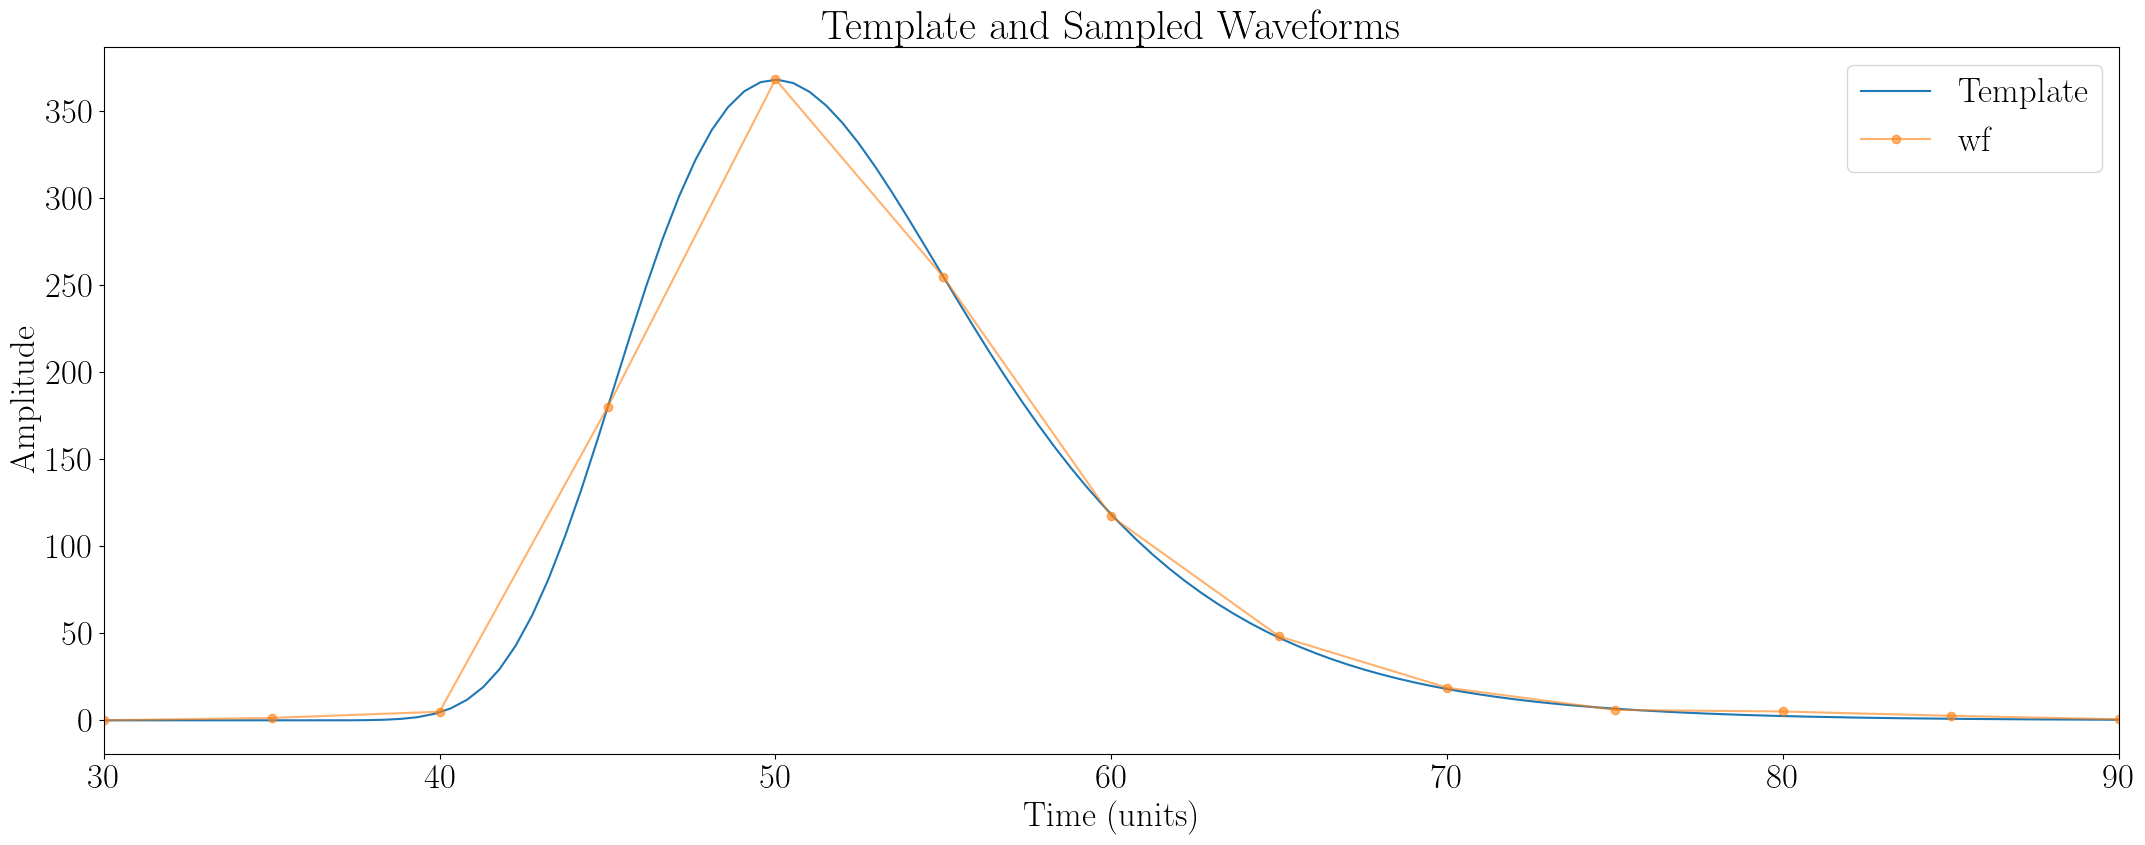

In [5]:
wfs = []
mus = []
wf, wf_mu = generate_wf( wf_len=WF_LEN, mu_min=MU_MIN, mu_max=MU_MIN, width=WIDTH, signal_to_noise_ratio=SIGNAL_TO_NOISE)
wf_time = np.linspace(0, WF_LEN-1, WF_LEN, endpoint=True)*DT

# Build the Gumbel template
x = np.linspace(0, WF_LEN-1, WF_LEN*UPSAMPLE_FACTOR, endpoint=True)
template = SIGNAL_TO_NOISE * gumbel_r.pdf(x, loc=wf_mu, scale=WIDTH)
template_time = x*DT

# Plot the template and a handful of sample wfs
fig, ax = plt.subplots(figsize=(22, 9))
ax.plot(template_time, template, label='Template')
ax.plot(wf_time, wf, label='wf', alpha=0.6, marker='o')


ax.set(
    xlabel='Time (units)',
    ylabel='Amplitude',
    title='Template and Sampled Waveforms',
    xlim=(30,90)
)
ax.legend()
fig.tight_layout()
plt.show()

In [12]:
wfs = []
mus = []
for _ in range(N_WFS):
    wf, mu = generate_wf( wf_len=WF_LEN, mu_min=MU_MIN, mu_max=MU_MAX, width=WIDTH, signal_to_noise_ratio=SIGNAL_TO_NOISE)
    wfs.append(wf)
    mus.append(mu)
wfs = np.vstack(wfs)
mus = np.array(mus)

foms = {}
for sigma in SIGMA_VALUES:
    mus_ext = np.random.normal(loc=mus, scale=sigma/DT)
    
#   mask = (mus_ext <= MU_MIN) | (mus_ext >= MU_MAX)
#   while mask.any():
#       mus_ext[mask] = np.random.normal(loc=mus[mask], scale=sigma/DT)
#       mask = (mus_ext <= MU_MIN) | (mus_ext >= MU_MAX)
        
    label = rf"external mu, $\sigma$ = {sigma} ns"
    foms[label] = mus_ext

similarity_fom = compute_comparison_matrix_sum(wfs)
foms["Pulse Shape"]= similarity_fom


rec_templates = {}

for label, fom in foms.items():
    reordered_wfs = reorder_wfs_by_fom(wfs, fom)
    upsampled_wfs = interpolate_averaged_wf(wfs=reordered_wfs, upsample_factor=UPSAMPLE_FACTOR)
    rec_templates[label] = upsampled_wfs

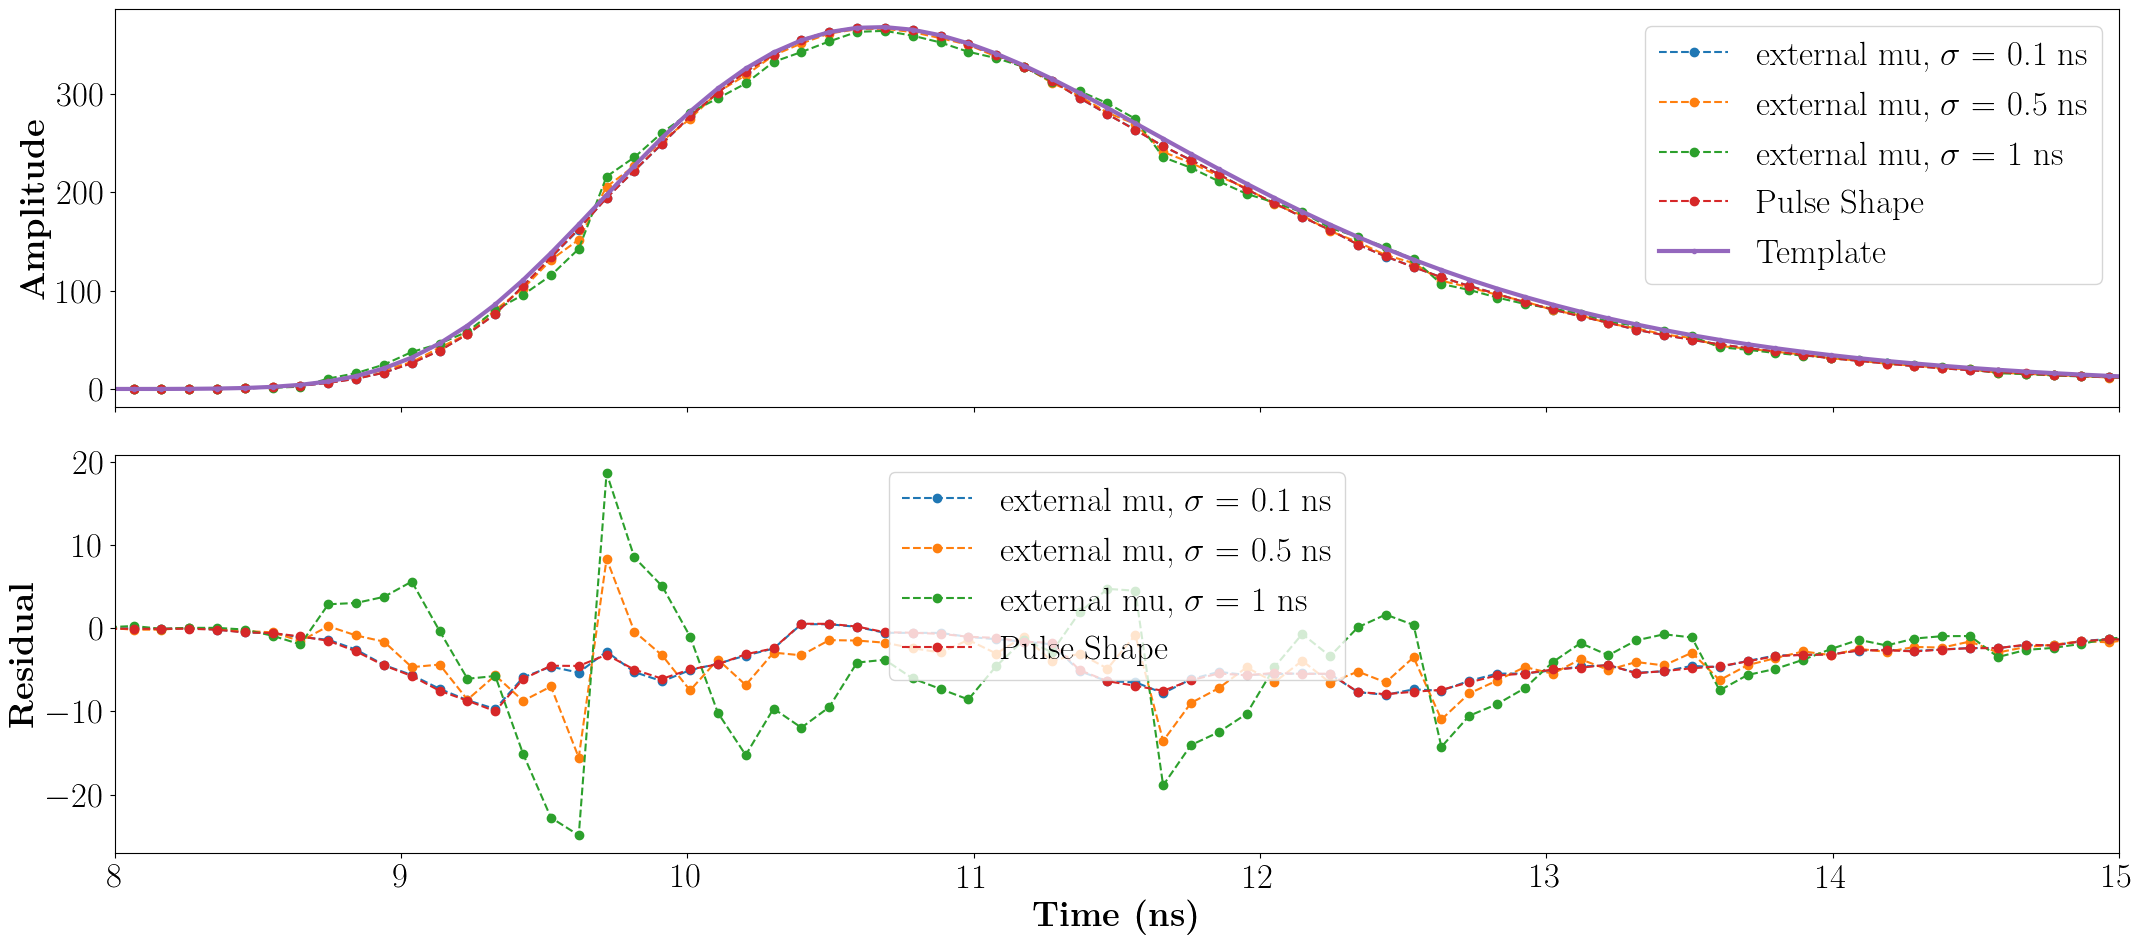

In [14]:
# Build template
# time samples of rec templates
rec_template_time = np.linspace(0, WF_LEN-1, WF_LEN*UPSAMPLE_FACTOR, endpoint=True)
template = SIGNAL_TO_NOISE * gumbel_r.pdf(rec_template_time, loc=(MU_MIN+MU_MAX)/2.+0.16, scale=WIDTH)

fig, axs = plt.subplots(2, 1, figsize=(22, 10), sharex=True)
plt.xlim(8,15)

for (label, wf) in rec_templates.items(): axs[0].plot(rec_template_time, wf,'--' ,label=label, marker="o")
axs[0].plot(rec_template_time, template, label="Template", marker="o", linewidth=3, markersize=3)
axs[0].set_ylabel(r"\textbf{Amplitude}")
axs[0].legend()

for (label, wf) in rec_templates.items():
    axs[1].plot(rec_template_time, (wf - template), '--', label=label, marker='o')

axs[1].set_xlabel(r"\textbf{Time (ns)}")
axs[1].set_ylabel(r"\textbf{Residual}")

plt.tight_layout()


plt.xlabel(r"\textbf{Time (ns)}")
plt.ylabel(r"\textbf{Residual}")
plt.legend()


plt.tight_layout()
plt.show()
